# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [138]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [139]:
def get_random_images(filepath, n=200):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [140]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [141]:
def get_imdb_data(imdb_id):
    """Fetch and parse IMDB page data."""
    url = f'https://www.imdb.com/title/{imdb_id}/'
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

    
    try:
        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.text, 'html.parser')
        script = soup.find('script', {'type': 'application/ld+json'})
        if not script:
            return None
        
        import json
        data = json.loads(script.string)
        
        show_data = {
            'imdb_id': imdb_id,
            'title': data.get('name', ''),
            'rating': data.get('aggregateRating', {}).get('ratingValue', 0),
            'rating_count': data.get('aggregateRating', {}).get('ratingCount', 0),
            'content_rating': data.get('contentRating', ''),
            'date_published': data.get('datePublished', ''),
            'genre_count': len(data.get('genre', [])),
        }
        
        return show_data
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [142]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate color histograms
    features = {}
    for i, color in enumerate(['blue', 'green', 'red']):
        hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        for j, value in enumerate(hist):
            features[f'{color}_bin_{j}'] = value
    
    return features

In [143]:
def create_dataset(image_folder):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    imdb_data = []
    feature_data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            features = extract_color_features(img_path)
            
            if features:
                features['imdb_id'] = imdb_id
                feature_data.append(features)
                imdb_data.append(show_data)
    
    imdb_df = pd.DataFrame(imdb_data)
    feature_df = pd.DataFrame(feature_data)
    
    # Save datasets
    imdb_df.to_csv('imdb_data.csv', index=False)
    feature_df.to_csv('feature_data.csv', index=False)
    
    
    return imdb_df, feature_df

In [144]:
def perform_pca_analysis(feature_df):
    """Perform PCA on features."""
    # Prepare feature matrix
    X = feature_df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    return pca, X_pca, n_components

In [145]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]  # Limit to n_components
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))  # Ensure x-ticks match the number of components
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines for better readability
    plt.show()

In [146]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [147]:
def plot_pca_features(pca, feature_names, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    # Get the feature loadings
    components = pca.components_
    
    # Create scatter plot
    for i, feature in enumerate(feature_names):
        plt.scatter(components[0, i], components[1, i])
        #plt.annotate(feature, (components[0, i], components[1, i]))
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [148]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [149]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 3D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131, projection='3d')
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    ax1.set_zlabel('PC3')
    
    # Hierarchical
    ax2 = fig.add_subplot(132, projection='3d')
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    ax2.set_zlabel('PC3')
    
    # DBSCAN
    ax3 = fig.add_subplot(133, projection='3d')
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], 
                          c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    ax3.set_zlabel('PC3')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [150]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
imdb_df, feature_df = create_dataset(IMAGE_FOLDER)   

Step 1: Gathering data...


In [151]:
print("\nIMDB Data Sample:")
imdb_df.head()


IMDB Data Sample:


,imdb_id,title,rating,rating_count,content_rating,date_published,genre_count
0,tt0100099,Mamono Hunter Yôko,6.400000,327,Not Rated,1990-12-01,3
1,tt1342141,Kommissar Klefisch,5.400000,14,,1990-01-07,1
2,tt0059995,The Hollywood Squares (Daytime),6.800000,1036,TV-PG,1965-04-21,3
3,tt1294801,Alpensaga,7.900000,42,,1976-10-24,1
4,tt0190169,3-2-1 Contact,8.200000,672,TV-Y7,1980-01-14,1


In [152]:
print("\nFeature Data Sample:")
feature_df.head()


Feature Data Sample:


,blue_bin_0,blue_bin_1,blue_bin_2,blue_bin_3,blue_bin_4,blue_bin_5,blue_bin_6,blue_bin_7,blue_bin_8,blue_bin_9,...,red_bin_247,red_bin_248,red_bin_249,red_bin_250,red_bin_251,red_bin_252,red_bin_253,red_bin_254,red_bin_255,imdb_id
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.072259,0.077839,0.081303,0.087172,0.086499,0.093427,0.113921,0.143459,0.319632,tt0100099
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000166,0.000332,0.000166,0.000664,0.000332,...,0.004678,0.005614,0.003625,0.002222,0.000936,0.000819,0.001169,0.000702,0.000117,tt1342141
2,0.000000,0.000169,0.000677,0.001861,0.000508,0.000846,0.002708,0.005246,0.006769,0.012015,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,tt0059995
3,0.364250,0.140687,0.056545,0.037809,0.031479,0.049371,0.039666,0.032661,0.037303,0.036628,...,0.003995,0.002935,0.004566,0.006931,0.010681,0.018101,0.024461,0.044111,0.447797,tt1294801
4,0.001873,0.004682,0.005619,0.008116,0.012486,0.018884,0.026532,0.041358,0.066017,0.110029,...,0.009360,0.009058,0.003472,0.000755,0.000604,0.000151,0.000302,0.000302,0.000000,tt0190169


In [153]:
# 4-8. PCA Analysis
print("\nStep 4-8: Performing PCA analysis...")
feature_names = feature_df.drop('imdb_id', axis=1).columns
pca, X_pca, n_components = perform_pca_analysis(feature_df)

# Set display precision for floating-point numbers
pd.set_option('display.float_format', '{:.6f}'.format)


print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
evr


Step 4-8: Performing PCA analysis...

Explained variance ratios:


,Explained Variance Ratio
Principal Component,
PC1,0.275797
PC2,0.115656
PC3,0.054507
PC4,0.042771
PC5,0.032463
...,...
PC196,0.000002
PC197,0.000001
PC198,0.000001


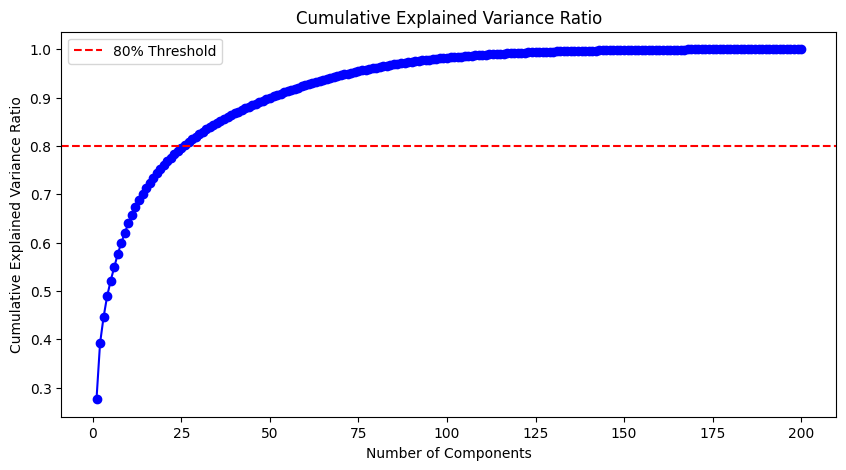

In [154]:
plot_cumulative_variance(pca)

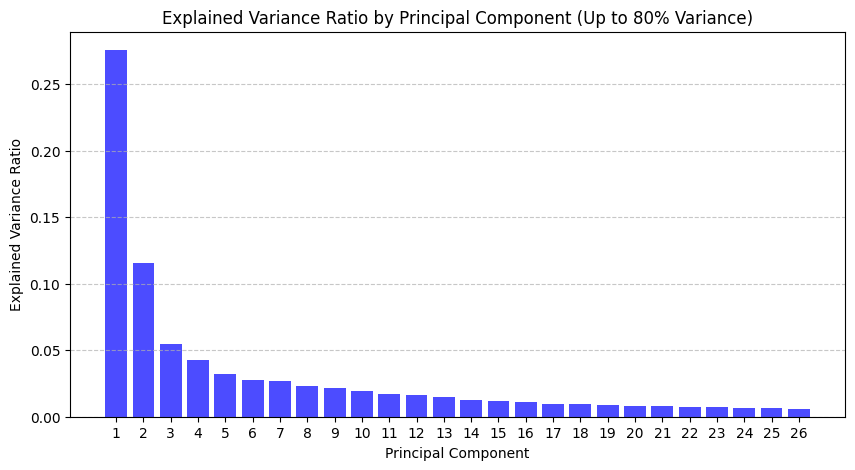

In [155]:
plot_explained_variance(pca, n_components)

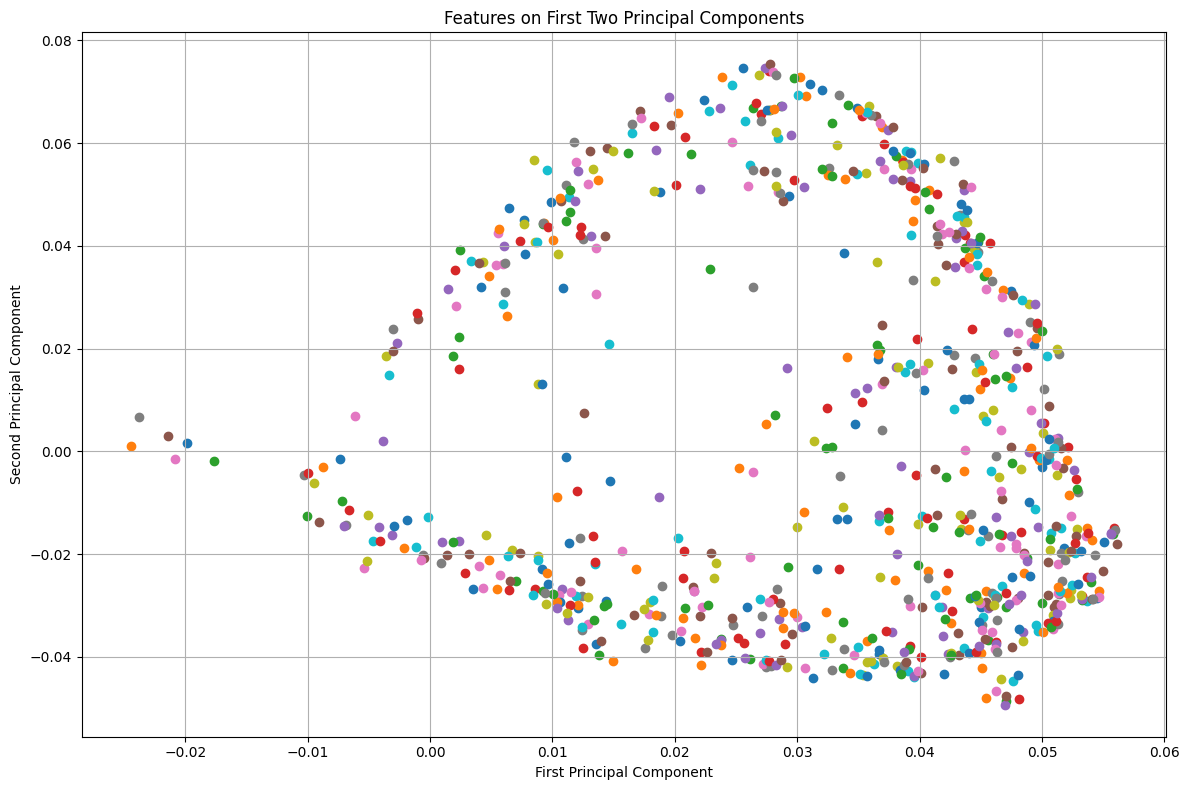

In [156]:
plot_pca_features(pca, feature_names, n_components)

In [157]:
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
loadings_df


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26
blue_bin_0,-0.290215,0.014646,-0.228034,-0.020571,-0.044183,0.075304,0.128226,0.004194,-0.095780,-0.004547,...,-0.085814,-0.004962,0.035347,-0.062477,-0.246380,-0.218223,0.026869,0.067217,0.027421,0.292040
blue_bin_1,-0.127940,-0.029131,-0.136618,0.011504,0.016117,0.244695,0.088839,0.003090,-0.034580,-0.063141,...,-0.131408,-0.030161,-0.004054,-0.085180,-0.147697,-0.251700,0.047318,0.151946,-0.151377,0.217979
blue_bin_2,-0.105092,-0.091686,-0.003202,0.037193,0.031177,0.267163,0.123957,-0.012007,0.018327,-0.059969,...,-0.143414,-0.085246,-0.032765,-0.119079,-0.066025,-0.180039,0.042164,0.081522,-0.177121,0.175917
blue_bin_3,-0.096985,-0.107701,0.036051,0.063748,0.020332,0.311583,0.134129,0.002853,0.031862,-0.064276,...,-0.137846,-0.074423,-0.008426,-0.112669,0.029133,-0.114742,0.048223,0.045086,-0.141176,0.119441
blue_bin_4,-0.060513,-0.139555,0.093355,0.135368,0.043732,0.433279,0.153851,0.041501,0.038397,-0.078139,...,-0.129590,-0.107850,-0.024854,-0.115533,0.138878,-0.076216,0.078557,0.004304,-0.115044,0.085621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
red_bin_251,-0.014952,0.254564,0.084169,-0.154403,0.190795,0.023655,-0.179586,0.027991,0.183519,-0.171171,...,-0.092679,-0.212807,-0.206057,-0.062178,0.171621,0.182919,0.074735,-0.162886,-0.124049,-0.039053
red_bin_252,-0.038792,0.199229,0.052862,-0.104877,0.141991,-0.028123,-0.138411,0.009010,0.120070,-0.121022,...,-0.052109,-0.165572,-0.241111,-0.026513,0.151985,0.126000,0.041283,-0.142421,-0.111443,0.005984
red_bin_253,-0.044191,0.185041,-0.005386,-0.116673,0.116101,-0.034351,-0.085134,0.002923,0.105542,-0.130028,...,-0.032995,-0.186696,-0.256936,-0.038753,0.186364,0.154502,0.038685,-0.136191,-0.082690,-0.065550
red_bin_254,-0.088959,0.064357,0.061712,-0.140494,0.106365,-0.076755,-0.111836,0.022869,0.108186,-0.122264,...,-0.004222,-0.266372,-0.331394,-0.014490,0.140200,0.165185,-0.010961,-0.081075,-0.115277,-0.046758


In [158]:
loadings_df.sort_values(by="PC1", ascending=False).head(10)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26
green_bin_109,0.818956,-0.170750,-0.158566,-0.203024,0.045155,0.209136,0.006668,0.078664,-0.030583,-0.190473,...,0.059955,-0.040471,0.002907,-0.057688,-0.016414,0.031495,0.098424,-0.009629,0.006223,0.050139
green_bin_111,0.816844,-0.143793,-0.144464,-0.202577,0.040749,0.156134,-0.021106,0.137390,-0.021025,-0.167211,...,0.008636,-0.013944,-0.012455,-0.081090,0.007028,0.009717,0.106358,-0.048048,0.023014,0.032638
green_bin_107,0.815516,-0.141637,-0.147530,-0.192733,0.026981,0.158722,0.016635,0.149662,-0.022406,-0.192143,...,0.040338,0.023736,0.009797,-0.043504,-0.045862,0.001234,0.149494,-0.036877,0.013398,0.040078
green_bin_106,0.814687,-0.152901,-0.162847,-0.184966,0.016111,0.195016,0.000745,0.151345,-0.037713,-0.197929,...,0.042191,0.008716,-0.028147,-0.021943,-0.032151,0.013463,0.153490,0.024615,0.022866,0.024013
green_bin_108,0.812226,-0.151039,-0.168960,-0.200711,0.018337,0.188053,0.018641,0.112105,-0.026253,-0.188645,...,0.060910,0.001878,-0.008630,-0.044584,-0.034045,0.022802,0.125233,-0.014248,-0.000822,0.043681
green_bin_118,0.811504,-0.151502,-0.174970,-0.136445,0.128382,0.155179,0.017591,0.098700,-0.100606,-0.199487,...,-0.011735,-0.036434,0.078437,0.021271,-0.011764,-0.000917,0.036657,-0.065187,0.031141,0.052051
green_bin_104,0.803096,-0.167445,-0.125638,-0.230036,0.010479,0.183690,-0.016446,0.150882,-0.031581,-0.199746,...,0.035706,0.009215,-0.009041,-0.048328,-0.013739,-0.019097,0.112955,0.033712,0.008412,-0.013745
green_bin_99,0.802176,-0.220679,-0.099793,-0.226232,-0.032304,0.173913,0.005545,0.056677,-0.016840,-0.203127,...,0.050920,-0.025873,0.012934,-0.108137,-0.026250,0.006861,0.085161,0.042197,0.033091,0.006984
green_bin_95,0.797860,-0.256904,-0.059546,-0.248764,-0.072713,0.141139,0.006428,-0.006118,0.016945,-0.184211,...,0.036496,0.002316,0.057982,-0.150216,-0.023969,0.017454,0.072146,0.021526,0.022141,0.001788
red_bin_94,0.797121,-0.268022,-0.050112,-0.217577,0.007494,0.028461,0.132147,-0.307369,0.013233,-0.096647,...,0.112119,0.010198,-0.053983,0.087985,-0.075871,0.018046,0.037920,0.051567,0.012573,0.022205



Step 9-12: Performing clustering analysis...


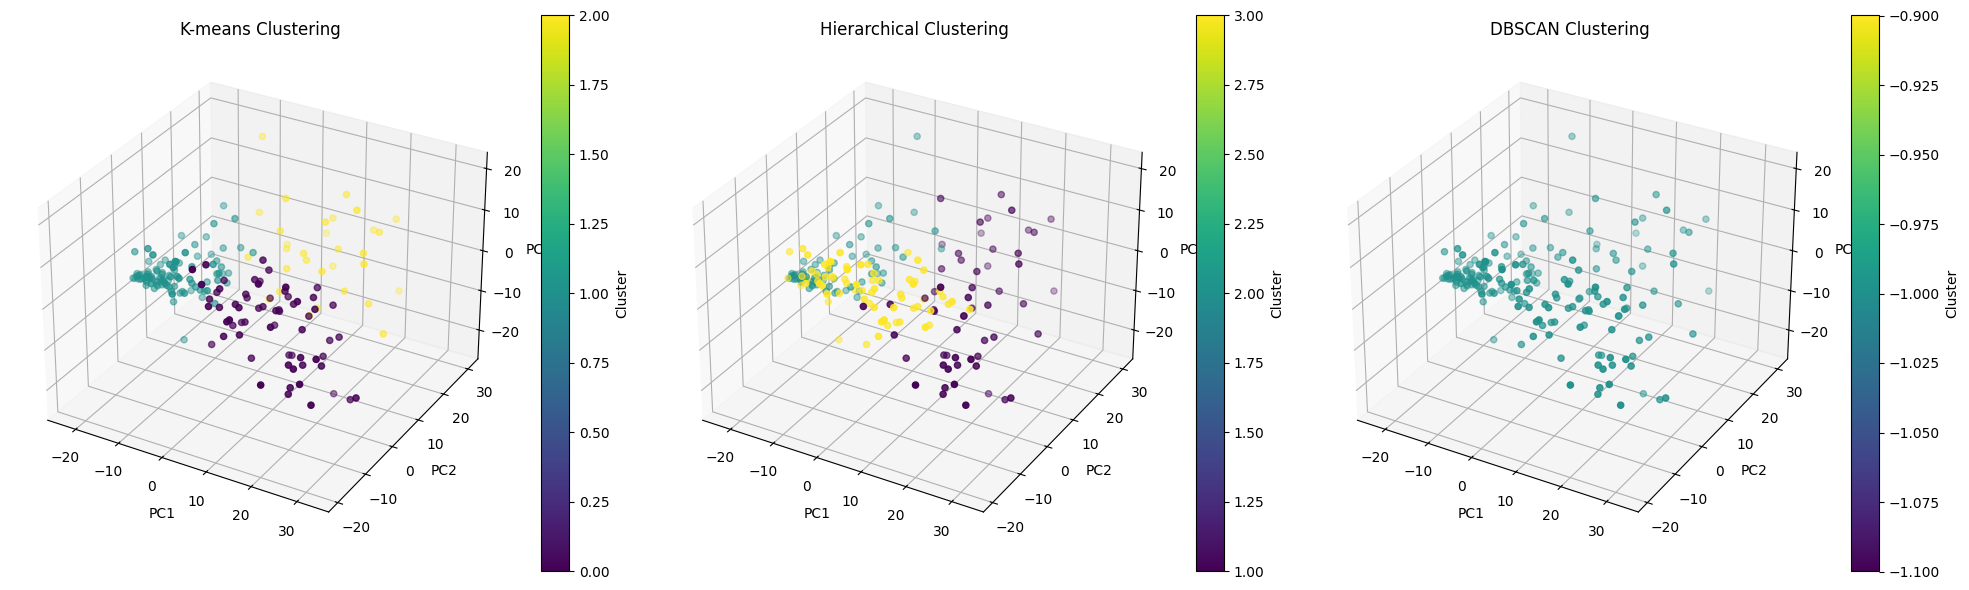

In [159]:
# 9-12. Clustering Analysis
print("\nStep 9-12: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)